# TCS Amsterdam Marathon ? Participant Performance & Checkpoint Predictability Analysis

## Overview & Data Source
This notebook presents an exploratory and statistical analysis of participant results from the **TCS Amsterdam Marathon** event. All participant records, metadata, team classifications, and intermediate split timings were scraped directly from the official **MYLAPS Sporthive** results platform:

* **Source Website:** [TCS Amsterdam Marathon on MYLAPS Sporthive](https://sporthive.com/events/s/e5066f0f-f66c-405f-9983-15fbf286ec7d)
* **Scraper Script:** [`scrape_tcs_marathon.py`](scrape_tcs_marathon.py)
* **Master Dataset:** [`all_races_participants.csv`](all_races_participants.csv) (containing **17,760 participants** across the *TCS Marathon (42.2 km)*, *Samsung Galaxy 7.5K*, *Samsung Galaxy 7.5K Business Run*, *Heroes Run*, and three *Kids Runs*).

Each participant record includes demographic and category metadata (`gender`, `country`, `city`, `race_category`, and derived `age_bracket`, `age_min`, `age_max`), official finishing times (`chip_time` and `gun_time`), and?for the main races?complete intermediate checkpoint splits (`total_time`, `split_time`, and `speed_kmh`).

---

## Structure of This Notebook

This analysis is organized into **two main sections**, each addressing a core research question:

### Part 1: What Effect Does Age (and Gender) Have on Finishing Times?
> **Hypothesis:** *"The older you are, the slower you are."*

Since exact dates of birth are not publicly exposed for privacy reasons, we derive numeric age brackets from the official Dutch athletics category codes (`race_category`):
* **Adult Races (*TCS Marathon* & *Samsung Galaxy 7.5K*):** Grouped into Seniors (`18?34`) and 5-year Masters age brackets (`35?39`, `40?44`, `45?49`, ?, `80+`) for both Men (`M`) and Women (`F/V`).
* **Kids Runs (*1.000m 4?6 yrs*, *1.000m 7?9 yrs*, and *1.600m*):** Encoded with the child's exact age in years (`4` through `12`).

In **Sections 1?6**, we aggregate and plot average and median finishing times (with 95% confidence intervals) and normalized running pace (`min/km`) across every race, age bucket, and gender. The visualizations confirm a clear **lifespan U-curve**:
1. **Childhood (`Ages 4 ? 12`):** Older children run progressively **faster** as they grow taller and stronger.
2. **Adulthood (`Ages 18?34 ? 80+`):** Across both adult distances and both genders, average finishing times steadily **increase** (and running speed decreases) with each successive age bracket, with a pronounced slowdown accelerating after age 50?55.

---

### Part 2: Can We Predict the Final Marathon Ranking in Advance (and Shorten the Race)?
> **Hypothesis:** *Can intermediate checkpoints at 5 km, 10 km, or 20 km already tell us who wins the 42.195 km TCS Marathon?or predict the final order of the entire field?so that runners could theoretically stop early?*

Using the 9 official timing mats along the **42.195 km TCS Marathon** course (`5 km`, `10 km`, `15 km`, `20 km`, `21.1 km Half`, `25 km`, `30 km`, `35 km`, and `40 km`), we investigate three aspects of race predictability:

1. **Crowning the Overall Winner & Top-10 Podium (Section 2.1):**
   * By tracking the checkpoint rank trajectory (*bump chart*) of the eventual Top 10 finishers, we test whether early leaders hold onto their positions.
   * **Finding:** Tactical pack running makes early checkpoints poor predictors of the podium?the eventual champion (**Lemi Berhanu**, `02:03:33`) was ranked **10th at 20 km** and **6th at 35 km**, only taking 1st place at **40 km**.

2. **Predicting the Entire Field ? Single Checkpoint vs. Combined Checkpoints (Section 2.2):**
   * Across all **5,738 complete finishers**, we compare a **Single Checkpoint model** (using only cumulative time at distance $X$) against a **Combined Checkpoints model** (combining `5 km + 10 km + ? + X km` via linear regression).
   * **Finding:** Combining multiple checkpoints captures a runner's **pace trajectory (acceleration vs. deceleration)**, allowing a model at **20 km** (`Spearman ? = 0.9403`, `MAE = 3.31 min`) to match the accuracy of waiting for a single checkpoint at **25 km** (`Spearman ? = 0.9408`, `MAE = 3.32 min`)?effectively looking **5 km into the future**.

3. **Why We Still Cannot Shorten the Marathon ? "The 30?35 km Wall" (Section 2.3):**
   * Even when combining all splits up to 20 km, the average runner still shifts by **?380 rank positions** in the second half.
   * By grouping runners by their early pacing trend between `10 km` and `20 km`, we demonstrate how early pace decay foreshadows dramatic second-half time losses after **30 km** (*glycogen depletion / hitting the wall*), proving why the final 12 km remain the true test of the marathon.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep", font_scale=1.05)
plt.rcParams["figure.dpi"] = 120

## 1. Load & Prepare Participant Data

We parse `chip_time` (falling back to `gun_time` if needed) into seconds and minutes, and order age buckets chronologically using `age_min`.

In [2]:
df = pd.read_csv("all_races_participants.csv", low_memory=False)
print(f"Total rows loaded: {len(df):,}")
print("Races in dataset:", df["race_name"].value_counts().to_dict())

def parse_duration_to_seconds(val):
    if pd.isna(val):
        return np.nan
    s = str(val).strip()
    if not s:
        return np.nan
    parts = s.split(":")
    try:
        if len(parts) == 3:
            return int(parts[0]) * 3600 + int(parts[1]) * 60 + float(parts[2])
        elif len(parts) == 2:
            return int(parts[0]) * 60 + float(parts[1])
        return float(s)
    except ValueError:
        return np.nan

def format_seconds(sec, include_hours=True):
    if pd.isna(sec) or sec <= 0:
        return ""
    sec = int(round(sec))
    h = sec // 3600
    m = (sec % 3600) // 60
    s = sec % 60
    if include_hours or h > 0:
        return f"{h}:{m:02d}:{s:02d}"
    return f"{m}:{s:02d}"

df["finish_time_str"] = df["chip_time"].fillna(df["gun_time"])
df["finish_seconds"] = df["finish_time_str"].apply(parse_duration_to_seconds)
df["finish_minutes"] = df["finish_seconds"] / 60.0
df["pace_min_per_km"] = df["finish_minutes"] / (df["race_distance_meters"] / 1000.0)

# Standardize gender labels
gender_map = {"M": "Male (M)", "F": "Female (F/V)", "V": "Female (F/V)", "X": "Non-Binary / Other (X)"}
df["gender_label"] = df["gender"].map(gender_map).fillna(df["gender"])

# Filter to finishers with valid finish time and age_bracket
df_age = df.dropna(subset=["finish_seconds", "age_bracket", "age_min"]).copy()
df_age = df_age[df_age["age_bracket"].astype(str).str.strip() != ""]
df_age["age_min"] = df_age["age_min"].astype(int)

print(f"Participants with valid finish time and age bracket: {len(df_age):,}")
df_age[["race_name", "name", "gender", "race_category", "age_bracket", "finish_time_str", "finish_minutes"]].head(10)

Total rows loaded: 17,760
Races in dataset: {'Samsung Galaxy 7.5K': 8589, 'TCS Marathon': 5766, 'Samsung Galaxy 7.5K Business Run': 1103, 'Kids Run 1.000m (4 - 6 years)': 1033, 'Kids Run 1.000m (7 - 9 years)': 740, 'Kids Run 1.600m': 494, 'Heroes Run': 35}
Participants with valid finish time and age bracket: 16,594


,race_name,name,gender,race_category,age_bracket,finish_time_str,finish_minutes
0,TCS Marathon,Lemi Berhanu,M,Msen,18-34,02:03:33,123.550000
1,TCS Marathon,Nicholas Kipkorir,M,Msen,18-34,02:03:39,123.650000
2,TCS Marathon,Patrick Mosin,M,Msen,18-34,02:03:58,123.966667
3,TCS Marathon,Kalipus Lomwai,M,Msen,18-34,02:04:08,124.133333
4,TCS Marathon,Sila Kiptoo,M,Msen,18-34,02:04:12,124.200000
5,TCS Marathon,Justus Kangogo,M,Msen,18-34,02:04:24,124.400000
6,TCS Marathon,Jonathan Korir,M,Msen,18-34,02:04:52,124.866667
7,TCS Marathon,Isaia Lasoi,M,Msen,18-34,02:04:57,124.950000
8,TCS Marathon,Yohei Ikeda,M,Msen,18-34,02:05:16,125.266667
9,TCS Marathon,Yihunilign Adane,M,Msen,18-34,02:05:16,125.266667


## 2. Summary Table: Average Finishing Time per Race, Age Bucket & Gender

In [3]:
summary = (
    df_age[df_age["gender"].isin(["M", "F", "V"])]
    .groupby(["race_name", "age_min", "age_bracket", "gender_label"], as_index=False)
    .agg(
        participants=("finish_seconds", "count"),
        avg_finish_seconds=("finish_seconds", "mean"),
        median_finish_seconds=("finish_seconds", "median"),
        p25_finish_seconds=("finish_seconds", lambda s: np.percentile(s, 25)),
        p75_finish_seconds=("finish_seconds", lambda s: np.percentile(s, 75)),
        std_finish_seconds=("finish_seconds", "std"),
        avg_finish_minutes=("finish_minutes", "mean"),
        p25_finish_minutes=("finish_minutes", lambda s: np.percentile(s, 25)),
        p75_finish_minutes=("finish_minutes", lambda s: np.percentile(s, 75)),
        avg_pace_min_km=("pace_min_per_km", "mean"),
    )
    .sort_values(["race_name", "age_min", "gender_label"])
)

summary["avg_finish_time"] = summary["avg_finish_seconds"].apply(lambda s: format_seconds(s, include_hours=True))
summary["median_finish_time"] = summary["median_finish_seconds"].apply(lambda s: format_seconds(s, include_hours=True))
summary["p25_finish_time"] = summary["p25_finish_seconds"].apply(lambda s: format_seconds(s, include_hours=True))
summary["p75_finish_time"] = summary["p75_finish_seconds"].apply(lambda s: format_seconds(s, include_hours=True))

display_cols = [
    "race_name", "age_bracket", "gender_label", "participants",
    "avg_finish_time", "p25_finish_time", "median_finish_time", "p75_finish_time", "avg_pace_min_km"
]
summary[display_cols].head(30)

,race_name,age_bracket,gender_label,participants,avg_finish_time,p25_finish_time,median_finish_time,p75_finish_time,avg_pace_min_km
0,Kids Run 1.000m (4 - 6 years),4,Female (F/V),128,0:08:44,0:07:40,0:08:30,0:09:17,8.731120
1,Kids Run 1.000m (4 - 6 years),4,Male (M),140,0:08:20,0:07:22,0:08:11,0:08:54,8.328214
2,Kids Run 1.000m (4 - 6 years),5,Female (F/V),170,0:07:52,0:07:10,0:07:44,0:08:20,7.873235
3,Kids Run 1.000m (4 - 6 years),5,Male (M),204,0:07:19,0:06:34,0:07:06,0:07:54,7.317974
4,Kids Run 1.000m (4 - 6 years),6,Female (F/V),156,0:07:08,0:06:32,0:07:01,0:07:45,7.138141
5,Kids Run 1.000m (4 - 6 years),6,Male (M),206,0:06:35,0:05:50,0:06:28,0:07:10,6.582443
6,Kids Run 1.000m (4 - 6 years),7,Female (F/V),7,0:07:06,0:06:26,0:06:54,0:07:50,7.095238
7,Kids Run 1.000m (4 - 6 years),7,Male (M),5,0:06:47,0:06:10,0:06:35,0:06:41,6.783333
8,Kids Run 1.000m (4 - 6 years),8,Female (F/V),7,0:07:46,0:07:08,0:07:35,0:08:21,7.771429
9,Kids Run 1.000m (4 - 6 years),8,Male (M),6,0:06:20,0:05:16,0:06:24,0:07:00,6.333333


## 3. Adult Races: "The Older You Are, The Slower You Are"

Below we plot the **average finishing time** across adult age buckets (`18-34` up to `80+`) by gender for:
1. **TCS Marathon (42.195 km)**
2. **Samsung Galaxy 7.5K (7.5 km)**

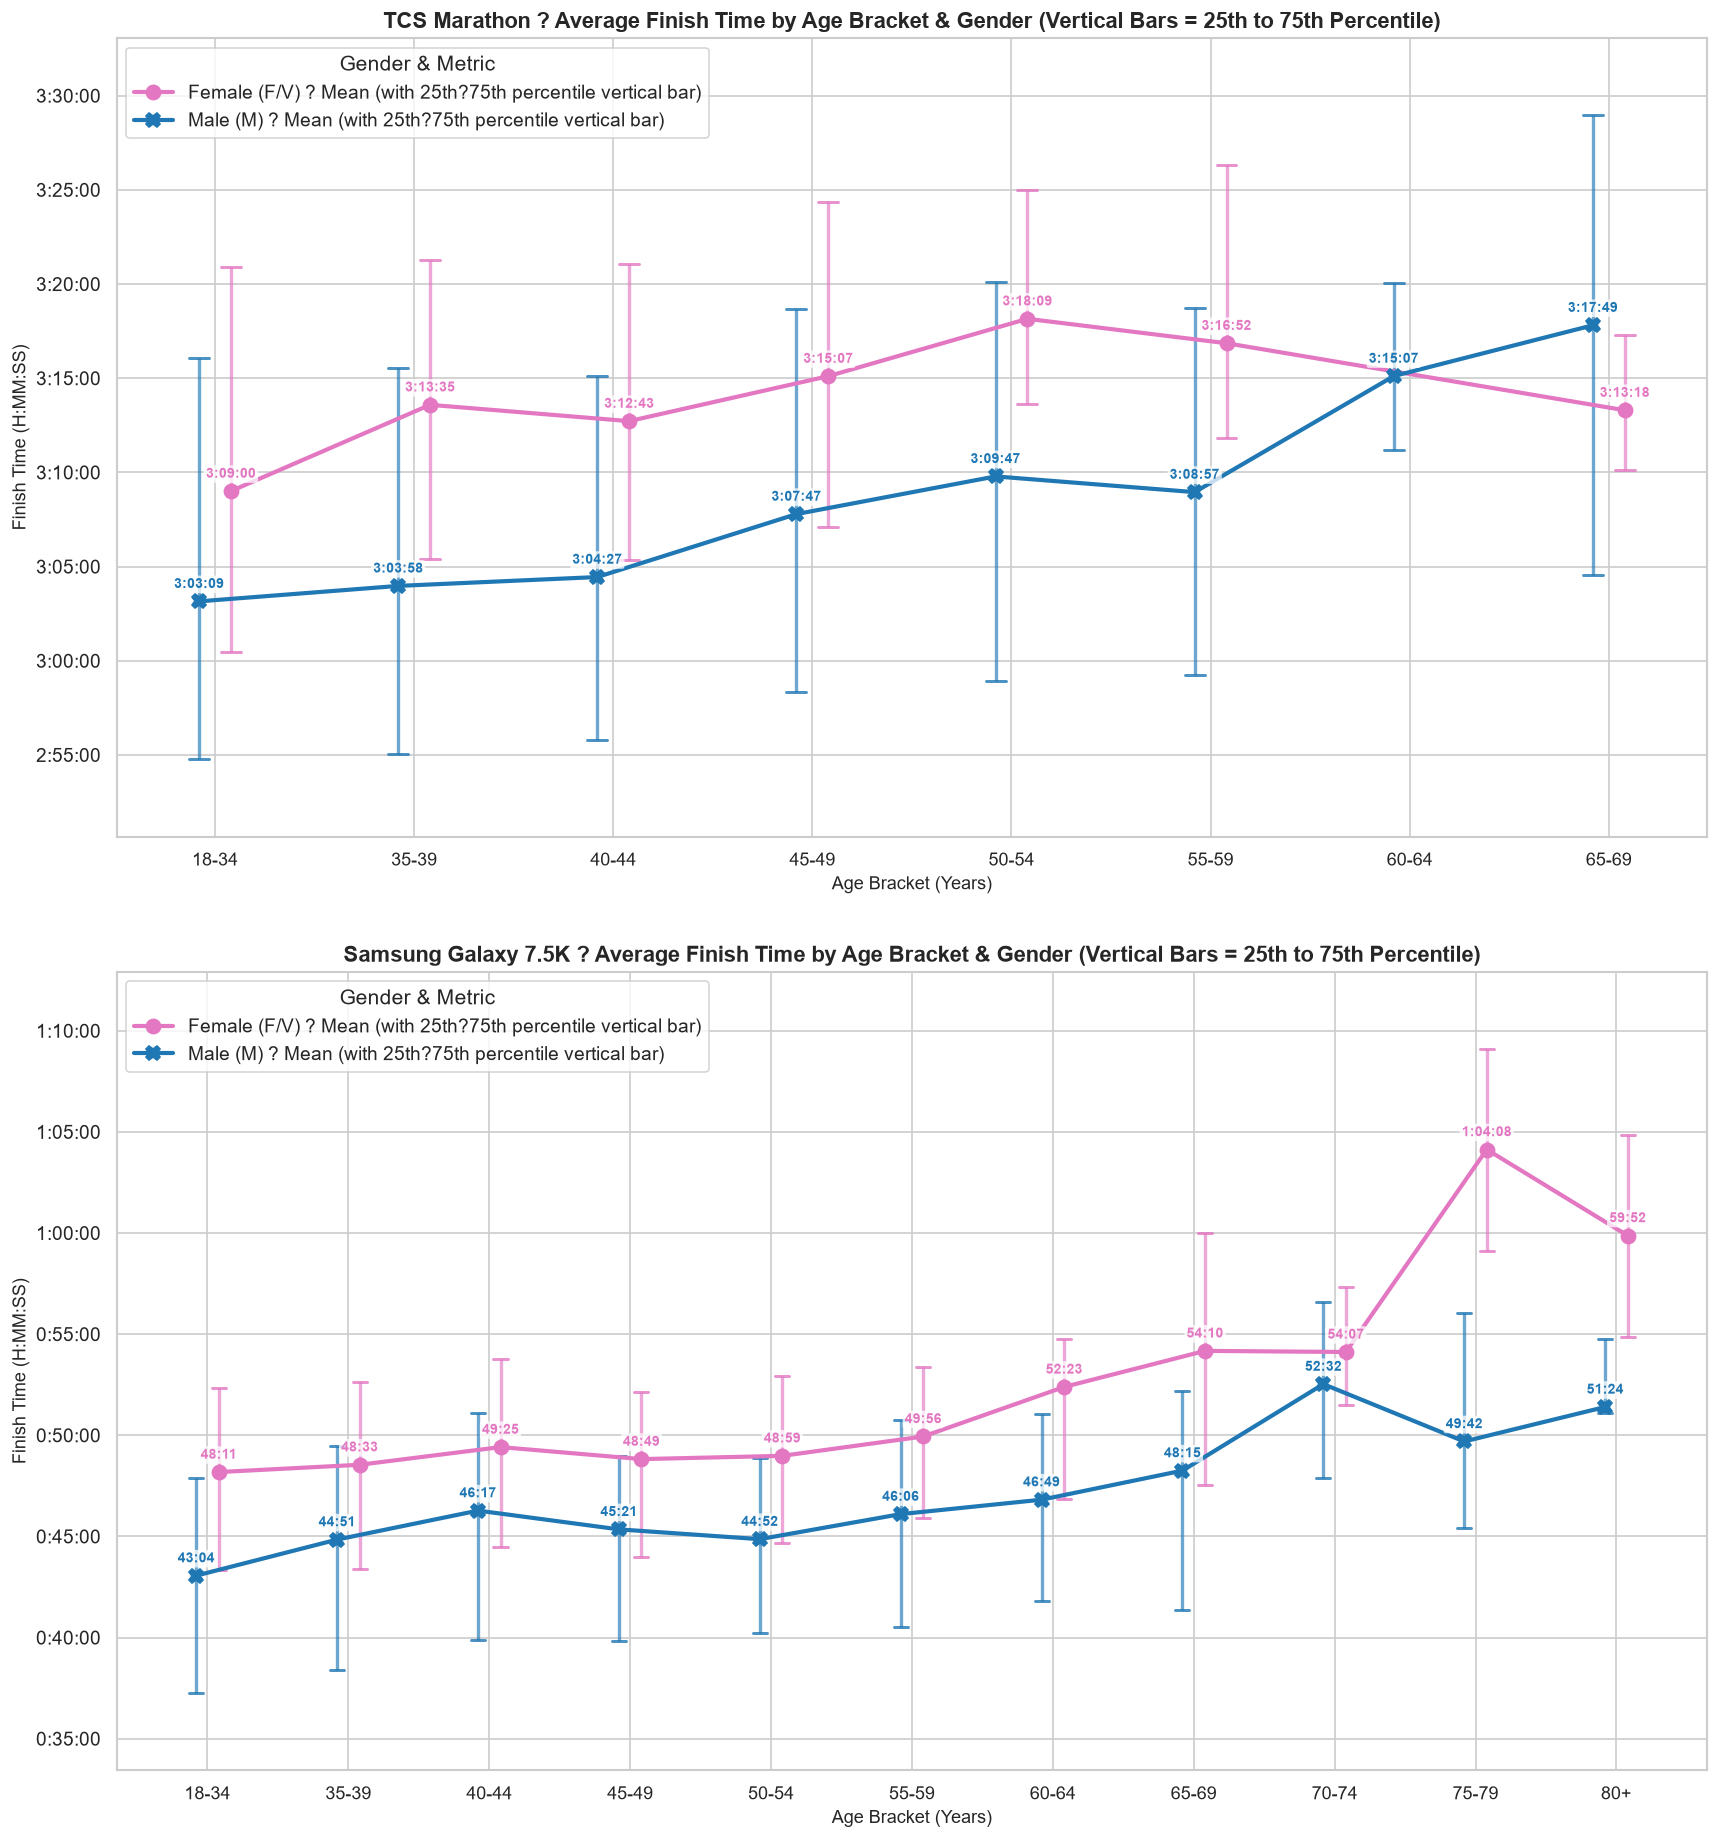

In [4]:
adult_races = ["TCS Marathon", "Samsung Galaxy 7.5K"]
palette = {"Male (M)": "#1f77b4", "Female (F/V)": "#e377c2"}
markers_map = {"Male (M)": "X", "Female (F/V)": "o"}
offsets_map = {"Male (M)": -0.08, "Female (F/V)": 0.08}

# Stacked vertically (2 rows, 1 column) so each plot is wide and easy to read
fig, axes = plt.subplots(2, 1, figsize=(15, 16), sharex=False)

for ax, race_name in zip(axes, adult_races):
    sub = summary[(summary["race_name"] == race_name) & (summary["participants"] >= 2)].copy()
    sub = sub.sort_values("age_min")
    age_order = sub.drop_duplicates("age_bracket").sort_values("age_min")["age_bracket"].tolist()
    x_lookup = {b: i for i, b in enumerate(age_order)}

    for gender_label in ["Female (F/V)", "Male (M)"]:
        gsub = sub[sub["gender_label"] == gender_label].sort_values("age_min")
        if gsub.empty:
            continue

        x_vals = np.array([x_lookup[b] + offsets_map[gender_label] for b in gsub["age_bracket"]])
        y_mean = gsub["avg_finish_minutes"].values
        y_p25 = gsub["p25_finish_minutes"].values
        y_p75 = gsub["p75_finish_minutes"].values
        color = palette[gender_label]

        # Plot line + markers for average finish time
        ax.plot(
            x_vals,
            y_mean,
            marker=markers_map[gender_label],
            color=color,
            linewidth=2.5,
            markersize=8.5,
            label=f"{gender_label} ? Mean (with 25th?75th percentile vertical bar)",
            zorder=4,
        )

        # Draw vertical lines from 25th percentile to 75th percentile with end caps
        ax.vlines(
            x_vals,
            y_p25,
            y_p75,
            color=color,
            linestyle="-",
            linewidth=2.0,
            alpha=0.65,
            zorder=3,
        )
        cap_half_width = 0.05
        for xv, p25_v, p75_v in zip(x_vals, y_p25, y_p75):
            ax.plot([xv - cap_half_width, xv + cap_half_width], [p25_v, p25_v], color=color, lw=1.8, alpha=0.8, zorder=3)
            ax.plot([xv - cap_half_width, xv + cap_half_width], [p75_v, p75_v], color=color, lw=1.8, alpha=0.8, zorder=3)

        # Annotate mean time at each point
        include_hr = (race_name == "TCS Marathon")
        for xv, row in zip(x_vals, gsub.itertuples()):
            label_str = format_seconds(row.avg_finish_seconds, include_hours=include_hr)
            ax.annotate(
                label_str,
                (xv, row.avg_finish_minutes),
                textcoords="offset points",
                xytext=(0, 8),
                ha="center",
                fontsize=8.5,
                fontweight="bold",
                color=color,
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.75),
                zorder=5,
            )

    ax.set_xticks(range(len(age_order)))
    ax.set_xticklabels(age_order, fontsize=10.5)
    ax.set_title(
        f"{race_name} ? Average Finish Time by Age Bracket & Gender (Vertical Bars = 25th to 75th Percentile)",
        fontsize=13,
        fontweight="bold",
    )
    ax.set_xlabel("Age Bracket (Years)", fontsize=11)
    ax.set_ylabel("Finish Time (H:MM:SS)", fontsize=11)
    ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda mins, pos: format_seconds(mins * 60, include_hours=True)))
    ax.margins(y=0.12)
    ax.legend(title="Gender & Metric", loc="upper left", frameon=True)

plt.tight_layout(pad=2.5)
plt.show()

## 4. Grouped Bar Charts with Error Bars (95% CI) for Adult Races

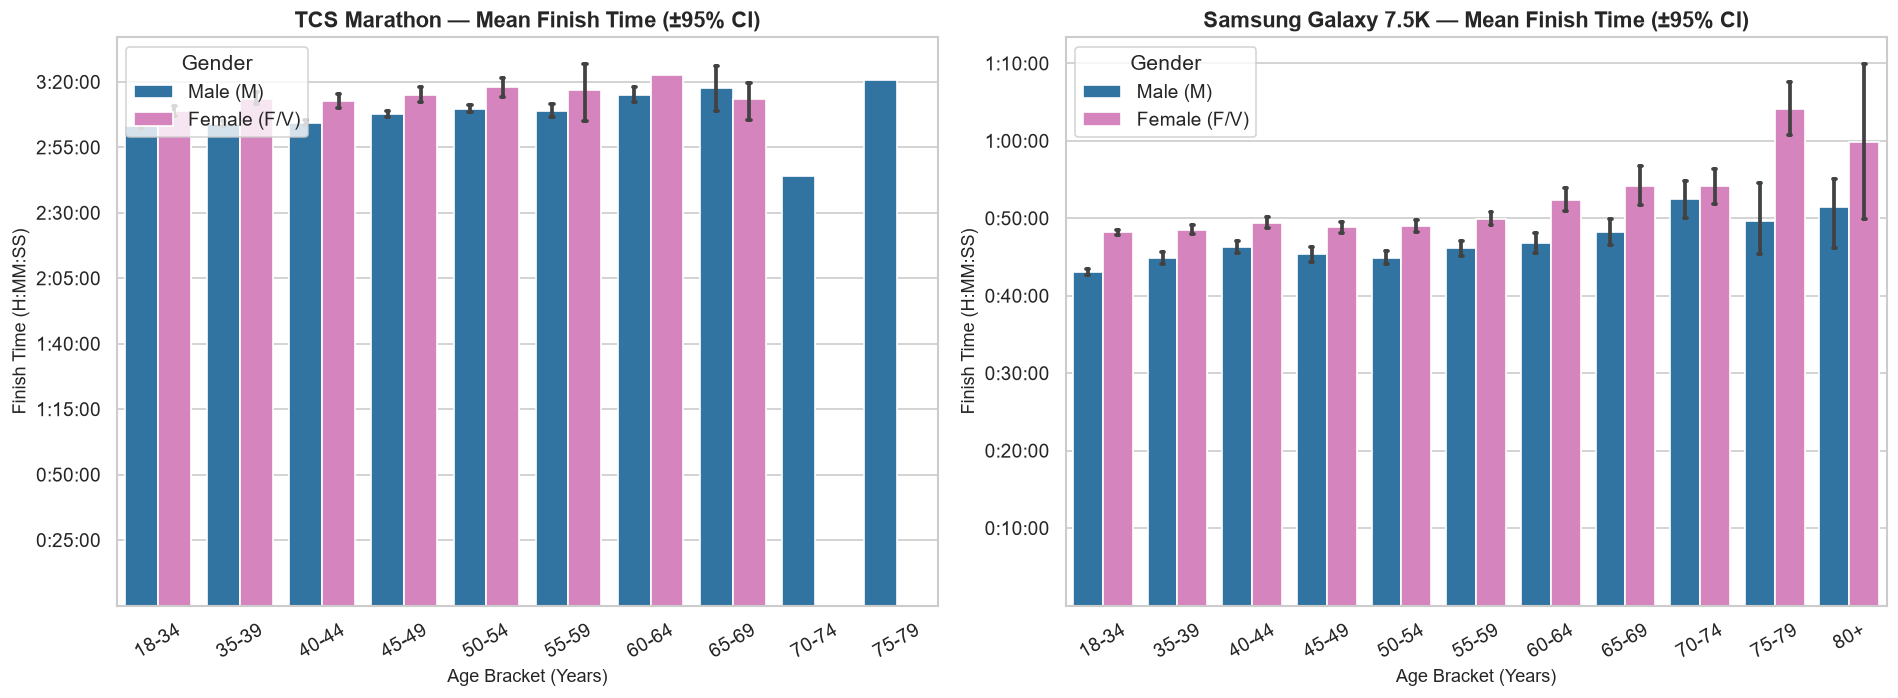

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, race_name in zip(axes, adult_races):
    sub_raw = df_age[
        (df_age["race_name"] == race_name) & (df_age["gender"].isin(["M", "F", "V"]))
    ].sort_values("age_min")
    age_order = sub_raw.drop_duplicates("age_bracket").sort_values("age_min")["age_bracket"].tolist()

    sns.barplot(
        data=sub_raw,
        x="age_bracket",
        y="finish_minutes",
        hue="gender_label",
        order=age_order,
        palette=palette,
        errorbar=("ci", 95),
        capsize=0.08,
        ax=ax,
    )

    ax.set_title(f"{race_name} — Mean Finish Time (±95% CI)", fontsize=13, fontweight="bold")
    ax.set_xlabel("Age Bracket (Years)", fontsize=11)
    ax.set_ylabel("Finish Time (H:MM:SS)", fontsize=11)
    ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda mins, pos: format_seconds(mins * 60, include_hours=True)))
    ax.tick_params(axis="x", rotation=30)
    ax.legend(title="Gender", loc="upper left")

plt.tight_layout()
plt.show()

## 5. Kids Runs: Average Finishing Time by Exact Age & Gender

In contrast to adult races, in the **Kids Runs** (`4–12` years old), getting older makes runners **faster** as children grow taller and stronger:

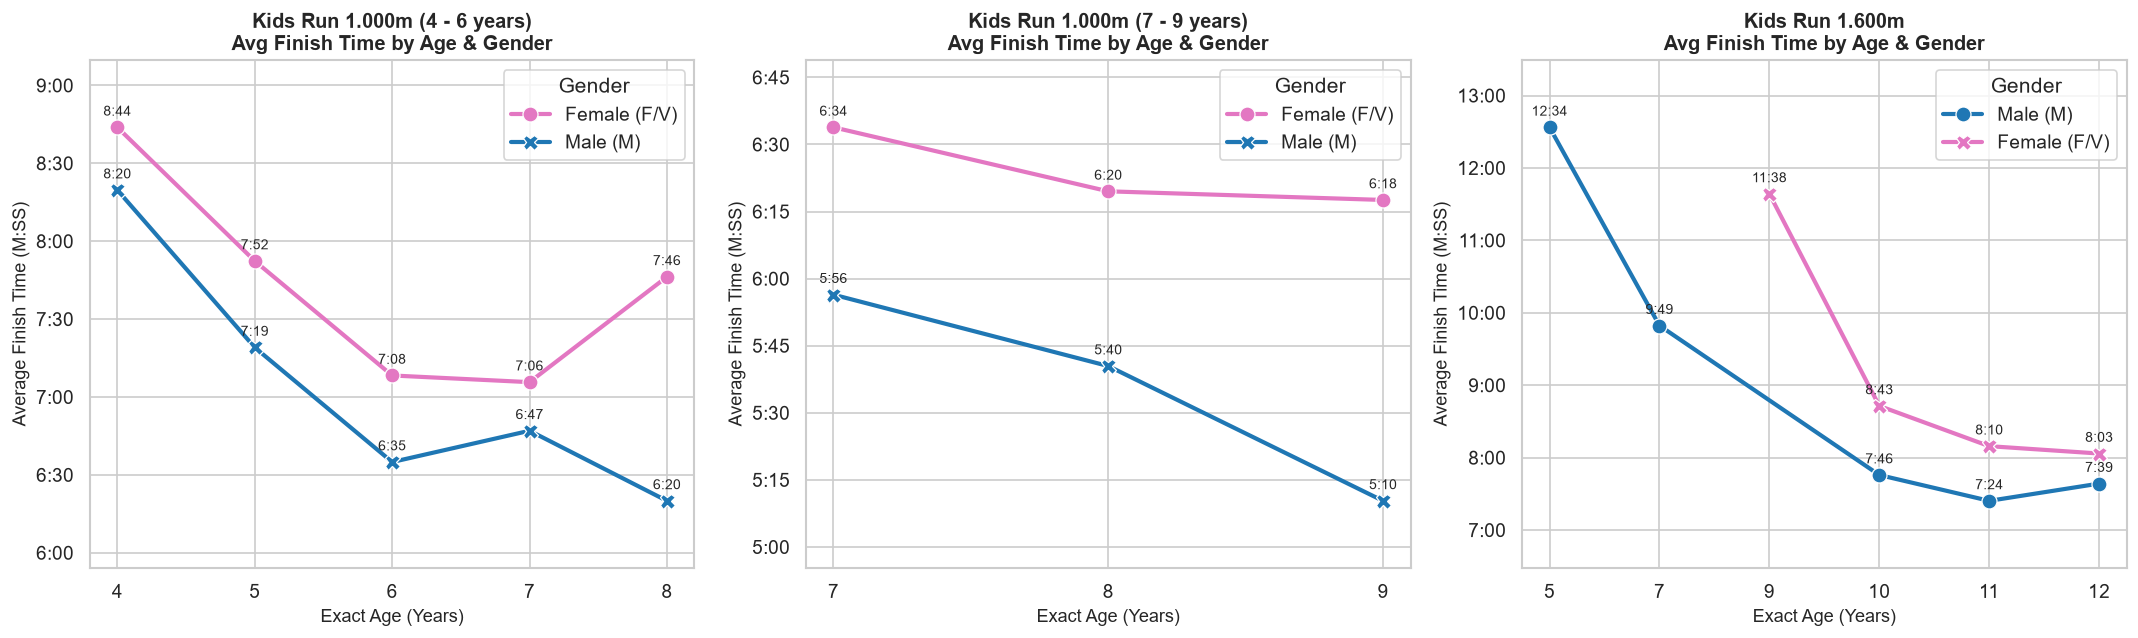

In [6]:
kids_races = [
    "Kids Run 1.000m (4 - 6 years)",
    "Kids Run 1.000m (7 - 9 years)",
    "Kids Run 1.600m",
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharey=False)

for ax, race_name in zip(axes, kids_races):
    sub = summary[(summary["race_name"] == race_name) & (summary["participants"] >= 3)].copy()
    sub = sub.sort_values("age_min")
    age_order = sub.drop_duplicates("age_bracket").sort_values("age_min")["age_bracket"].tolist()

    sns.lineplot(
        data=sub,
        x="age_bracket",
        y="avg_finish_minutes",
        hue="gender_label",
        style="gender_label",
        markers=True,
        dashes=False,
        linewidth=2.5,
        markersize=9,
        palette=palette,
        ax=ax,
    )

    for _, row in sub.iterrows():
        x_idx = age_order.index(row["age_bracket"])
        label_str = format_seconds(row["avg_finish_seconds"], include_hours=False)
        ax.annotate(
            label_str,
            (x_idx, row["avg_finish_minutes"]),
            textcoords="offset points",
            xytext=(0, 7),
            ha="center",
            fontsize=8.5,
        )

    ax.set_title(f"{race_name}\nAvg Finish Time by Age & Gender", fontsize=12, fontweight="bold")
    ax.set_xlabel("Exact Age (Years)", fontsize=11)
    ax.set_ylabel("Average Finish Time (M:SS)", fontsize=11)
    ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda mins, pos: format_seconds(mins * 60, include_hours=False)))
    ax.margins(y=0.18)
    ax.legend(title="Gender", loc="best")

plt.tight_layout()
plt.show()

## 6. All Races Combined: Normalized Pace (`min/km`) Across the Full Lifespan (Age 4 to 80+)

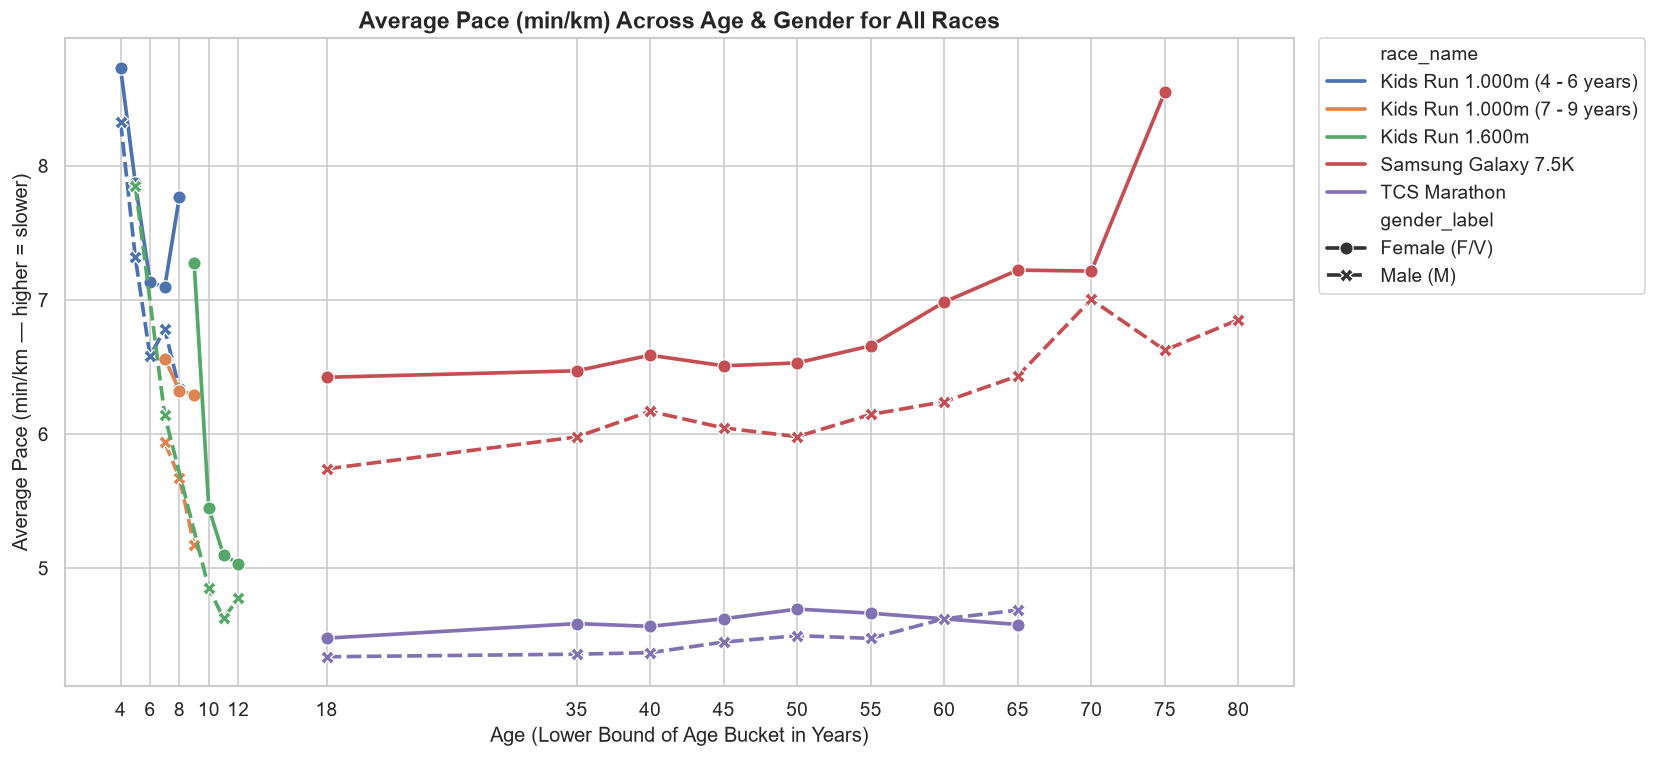

In [7]:
plt.figure(figsize=(14, 6.5))
sub_all = summary[summary["participants"] >= 3].copy()

sns.lineplot(
    data=sub_all,
    x="age_min",
    y="avg_pace_min_km",
    hue="race_name",
    style="gender_label",
    markers=True,
    linewidth=2.2,
    markersize=8,
)

plt.title("Average Pace (min/km) Across Age & Gender for All Races", fontsize=14, fontweight="bold")
plt.xlabel("Age (Lower Bound of Age Bucket in Years)", fontsize=12)
plt.ylabel("Average Pace (min/km — higher = slower)", fontsize=12)
plt.xticks([4, 6, 8, 10, 12, 18, 35, 40, 45, 50, 55, 60, 65, 70, 75, 80])
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0)
plt.tight_layout()
plt.show()

---
# Part 2: Can We Shorten the Marathon? Checkpoint Predictability Analysis (42.2 km)

We now focus on the **TCS Marathon (`42.195 km`)** and its 9 intermediate timing mats:
`5 km`, `10 km`, `15 km`, `20 km`, `21.1 km (Half)`, `25 km`, `30 km`, `35 km`, and `40 km`.

**Key Questions:**
1. **Can we already see the winner (and Top 10 podium) after 5, 10, or 20 km?**
2. **How well does each single checkpoint predict the final ranking and finish time across all ~5,760 finishers?**
3. **Does combining multiple checkpoints (capturing pace changes / deceleration) significantly improve the prediction?**

In [8]:
checkpoints = [
    ("5km", "5 KM", 5.0),
    ("10km", "10 KM", 10.0),
    ("15km", "15 KM", 15.0),
    ("20km", "20 KM", 20.0),
    ("21_1km", "21.1 KM (Half)", 21.0975),
    ("25km", "25 KM", 25.0),
    ("30km", "30 KM", 30.0),
    ("35km", "35 KM", 35.0),
    ("40km", "40 KM", 40.0),
]

marathon = df[df["race_name"] == "TCS Marathon"].copy()

for cp_key, cp_label, cp_dist in checkpoints:
    marathon[f"{cp_key}_sec"] = marathon[f"split_{cp_key}_total_time"].apply(parse_duration_to_seconds)
    marathon[f"{cp_key}_split_sec"] = marathon[f"split_{cp_key}_split_time"].apply(parse_duration_to_seconds)
    marathon[f"{cp_key}_rank"] = marathon[f"{cp_key}_sec"].rank(method="min")

marathon["final_rank"] = marathon["finish_seconds"].rank(method="min")

# Keep finishers who have valid split times across all 9 checkpoints
cp_sec_cols = [f"{cp_key}_sec" for cp_key, _, _ in checkpoints]
m_complete = marathon.dropna(subset=["finish_seconds"] + cp_sec_cols).copy()
m_complete["final_rank"] = m_complete["finish_seconds"].rank(method="average")
for cp_key, _, _ in checkpoints:
    m_complete[f"{cp_key}_rank"] = m_complete[f"{cp_key}_sec"].rank(method="average")

print(f"Total TCS Marathon finishers with all 9 checkpoints recorded: {len(m_complete):,}")

Total TCS Marathon finishers with all 9 checkpoints recorded: 5,714


## 2.1 Can We Crown the Winner Early? (Top 10 Finishers' Rank Trajectory)

Let's check the checkpoint rankings of the eventual **Top 10 finishers** from `5 km` to `42.2 km`:

In [9]:
top10 = marathon.sort_values("overall_position").head(10).copy()
rank_cols = [f"{cp_key}_rank" for cp_key, _, _ in checkpoints]

display_top10 = top10[["overall_position", "name", "chip_time"] + rank_cols].copy()
display_top10.columns = ["Final Pos", "Runner", "Finish Time"] + [cp_label for _, cp_label, _ in checkpoints]
for cp_label in [cp_label for _, cp_label, _ in checkpoints]:
    display_top10[cp_label] = display_top10[cp_label].astype(int)
display_top10

,Final Pos,Runner,Finish Time,5 KM,10 KM,15 KM,20 KM,21.1 KM (Half),25 KM,30 KM,35 KM,40 KM
0,1,Lemi Berhanu,02:03:33,6,3,9,10,10,7,9,6,1
1,2,Nicholas Kipkorir,02:03:39,17,14,9,10,10,7,9,6,1
2,3,Patrick Mosin,02:03:58,22,16,15,14,12,7,5,3,3
3,4,Kalipus Lomwai,02:04:08,19,3,3,3,12,7,9,3,4
4,5,Sila Kiptoo,02:04:12,6,3,9,3,2,2,5,3,4
5,6,Justus Kangogo,02:04:24,5,3,3,1,2,2,2,1,6
6,7,Jonathan Korir,02:04:52,14,3,9,10,12,2,2,1,8
7,8,Isaia Lasoi,02:04:57,2,3,3,3,2,2,5,6,7
8,9,Yohei Ikeda,02:05:16,6,3,9,10,9,2,14,13,11
9,10,Yihunilign Adane,02:05:16,10,16,15,14,16,14,9,10,9


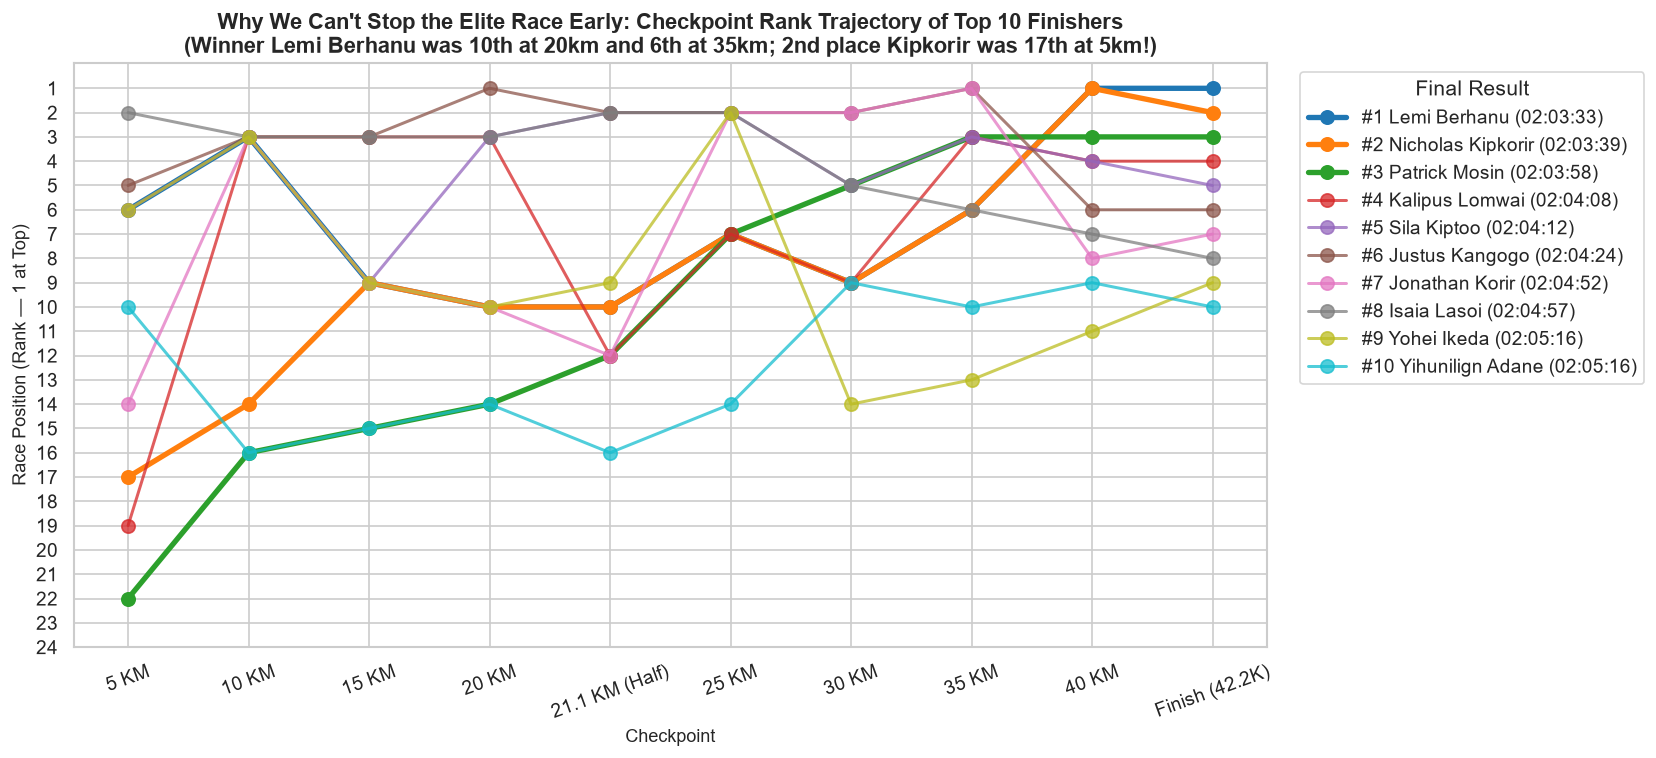

In [10]:
# Plot a Bump Chart showing how the Top 10 Finishers' rankings evolved at each checkpoint
fig, ax = plt.subplots(figsize=(14, 6.5))

x_labels = [cp_label for _, cp_label, _ in checkpoints] + ["Finish (42.2K)"]
x_positions = list(range(len(x_labels)))

cmap = plt.cm.tab10
for idx, (_, row) in enumerate(top10.iterrows()):
    ranks = [row[f"{cp_key}_rank"] for cp_key, _, _ in checkpoints] + [row["overall_position"]]
    color = cmap(idx % 10)
    lw = 3.2 if row["overall_position"] <= 3 else 1.8
    alpha = 1.0 if row["overall_position"] <= 3 else 0.75
    ax.plot(
        x_positions, ranks, marker="o", linewidth=lw, markersize=8,
        color=color, alpha=alpha,
        label=f"#{int(row['overall_position'])} {row['name']} ({row['chip_time']})"
    )

ax.invert_yaxis()  # Rank 1 at the top
ax.set_xticks(x_positions)
ax.set_xticklabels(x_labels, rotation=20)
ax.set_yticks(range(1, 25))
ax.set_title(
    "Why We Can't Stop the Elite Race Early: Checkpoint Rank Trajectory of Top 10 Finishers\n"
    "(Winner Lemi Berhanu was 10th at 20km and 6th at 35km; 2nd place Kipkorir was 17th at 5km!)",
    fontsize=13, fontweight="bold"
)
ax.set_xlabel("Checkpoint", fontsize=11)
ax.set_ylabel("Race Position (Rank — 1 at Top)", fontsize=11)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Final Result")
plt.tight_layout()
plt.show()

### Key Insight on the Winner:
* **No, we cannot crown the winner at 5 km, 10 km, 20 km, or even 35 km!**
* The eventual champion, **Lemi Berhanu (`02:03:33`)**, ran inside the tactical lead pack: he was **6th at 5 km**, **10th at 20 km & Half Marathon**, **9th at 30 km**, and still **6th at 35 km**—only breaking away to take **1st place at 40 km**.
* Runner-up **Nicholas Kipkorir (`02:03:39`)** was **17th at 5 km**, **14th at 10 km**, and **10th at 20 km**, while the 35 km co-leaders (**Justus Kangogo** and **Jonathan Korir**) faded in the final 7 km to finish **6th** and **7th**.

---
## 2.2 Single Checkpoint vs. Combining Checkpoints Across All 5,738 Finishers

What about predicting the finish time and ranking of **every runner in the race**?
We compare two models at each distance $d_k$:
1. **Single Checkpoint Model ($t_k$ only):** Predicts finish time using only the cumulative time at checkpoint $k$.
2. **Combined Checkpoints Model ($t_1, t_2, \dots, t_k$):** Uses **all checkpoints up to $k$** via linear regression. Because it includes earlier splits, the model automatically learns each runner's **pace trend / deceleration** (whether they are already slowing down or negative-splitting).

In [11]:
y_true = m_complete["finish_seconds"].values
final_rank = m_complete["final_rank"]

metrics_rows = []

for idx, (cp_key, cp_label, cp_dist) in enumerate(checkpoints):
    # 1. Single-checkpoint OLS prediction
    x_single = m_complete[f"{cp_key}_sec"].values
    X1 = np.column_stack([np.ones(len(m_complete)), x_single])
    beta1, _, _, _ = np.linalg.lstsq(X1, y_true, rcond=None)
    pred_single = X1 @ beta1
    rank_single = pd.Series(pred_single, index=m_complete.index).rank(method="average")

    mae_single_min = np.mean(np.abs(y_true - pred_single)) / 60.0
    r2_single = 1.0 - np.sum((y_true - pred_single) ** 2) / np.sum((y_true - y_true.mean()) ** 2)
    spearman_single = final_rank.corr(rank_single)
    rank_mae_single = np.mean(np.abs(final_rank - rank_single))

    # 2. Combined-checkpoints OLS prediction (all checkpoints from 5km up to cp_key)
    combo_cols = [f"{checkpoints[j][0]}_sec" for j in range(idx + 1)]
    Xk = np.column_stack([np.ones(len(m_complete)), m_complete[combo_cols].values])
    betak, _, _, _ = np.linalg.lstsq(Xk, y_true, rcond=None)
    pred_combo = Xk @ betak
    rank_combo = pd.Series(pred_combo, index=m_complete.index).rank(method="average")

    mae_combo_min = np.mean(np.abs(y_true - pred_combo)) / 60.0
    r2_combo = 1.0 - np.sum((y_true - pred_combo) ** 2) / np.sum((y_true - y_true.mean()) ** 2)
    spearman_combo = final_rank.corr(rank_combo)
    rank_mae_combo = np.mean(np.abs(final_rank - rank_combo))

    # Top-10 and Top-100 overlap
    true_top10 = set(m_complete.nsmallest(10, "finish_seconds")["bib"])
    single_top10 = set(m_complete.nsmallest(10, f"{cp_key}_sec")["bib"])
    true_top100 = set(m_complete.nsmallest(100, "finish_seconds")["bib"])
    single_top100 = set(m_complete.nsmallest(100, f"{cp_key}_sec")["bib"])

    metrics_rows.append({
        "Checkpoint": cp_label,
        "Distance (km)": cp_dist,
        "Single Spearman ρ": round(spearman_single, 4),
        "Combined Spearman ρ": round(spearman_combo, 4),
        "Single R²": round(r2_single, 4),
        "Combined R²": round(r2_combo, 4),
        "Single Time MAE (min)": round(mae_single_min, 2),
        "Combined Time MAE (min)": round(mae_combo_min, 2),
        "Single Rank Error (pos)": int(round(rank_mae_single)),
        "Combined Rank Error (pos)": int(round(rank_mae_combo)),
        "Top-10 Overlap": f"{len(true_top10 & single_top10)}/10",
        "Top-100 Overlap": f"{len(true_top100 & single_top100)}/100",
    })

metrics_df = pd.DataFrame(metrics_rows)
metrics_df

,Checkpoint,Distance (km),Single Spearman ρ,Combined Spearman ρ,Single R²,Combined R²,Single Time MAE (min),Combined Time MAE (min),Single Rank Error (pos),Combined Rank Error (pos),Top-10 Overlap,Top-100 Overlap
0,5 KM,5.0000,0.8963,0.8963,0.8371,0.8371,4.49,4.49,514,514,6/10,88/100
1,10 KM,10.0000,0.9069,0.9102,0.8552,0.8612,4.20,4.10,482,473,7/10,89/100
2,15 KM,15.0000,0.9168,0.9261,0.8701,0.8835,3.95,3.71,454,428,6/10,89/100
3,20 KM,20.0000,0.9269,0.9403,0.8851,0.9046,3.69,3.31,424,380,5/10,89/100
4,21.1 KM (Half),21.0975,0.9296,0.9420,0.8892,0.9070,3.62,3.25,415,373,5/10,90/100
5,25 KM,25.0000,0.9408,0.9553,0.9063,0.9243,3.32,2.84,380,323,9/10,90/100
6,30 KM,30.0000,0.9586,0.9760,0.9339,0.9597,2.77,1.97,316,225,7/10,93/100
7,35 KM,35.0000,0.9815,0.9911,0.9704,0.9855,1.82,1.10,207,127,9/10,94/100
8,40 KM,40.0000,0.9980,0.9993,0.9968,0.9989,0.59,0.30,67,35,9/10,97/100


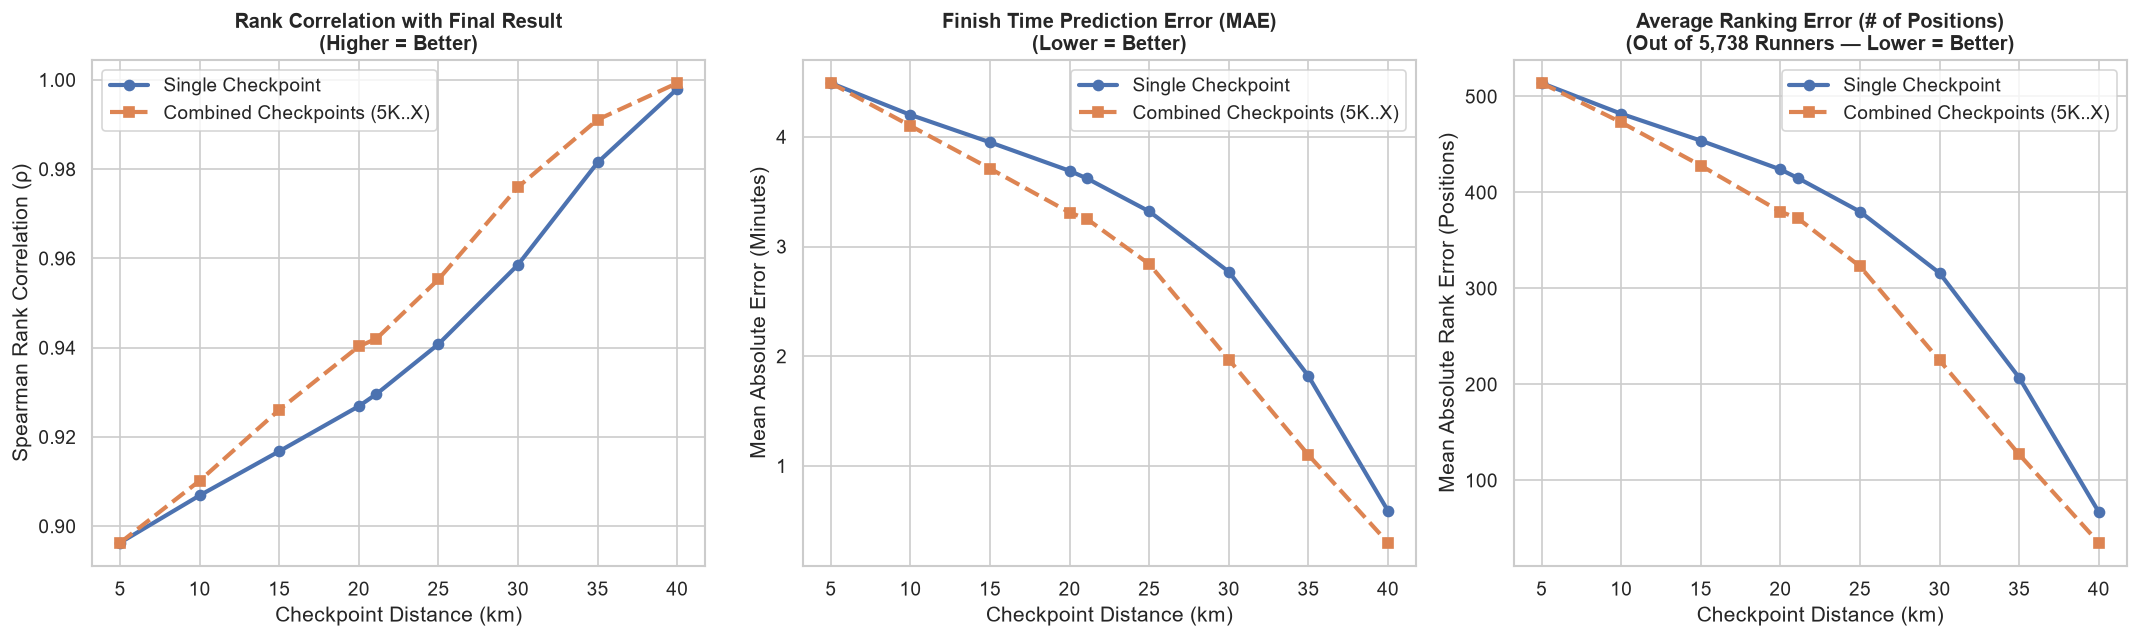

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# Plot 1: Spearman Rank Correlation
axes[0].plot(metrics_df["Distance (km)"], metrics_df["Single Spearman ρ"], marker="o", lw=2.5, label="Single Checkpoint")
axes[0].plot(metrics_df["Distance (km)"], metrics_df["Combined Spearman ρ"], marker="s", lw=2.5, linestyle="--", label="Combined Checkpoints (5K..X)")
axes[0].set_title("Rank Correlation with Final Result\n(Higher = Better)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Checkpoint Distance (km)")
axes[0].set_ylabel("Spearman Rank Correlation (ρ)")
axes[0].set_xticks([5, 10, 15, 20, 25, 30, 35, 40])
axes[0].legend()

# Plot 2: Finish Time Prediction Error (MAE in Minutes)
axes[1].plot(metrics_df["Distance (km)"], metrics_df["Single Time MAE (min)"], marker="o", lw=2.5, label="Single Checkpoint")
axes[1].plot(metrics_df["Distance (km)"], metrics_df["Combined Time MAE (min)"], marker="s", lw=2.5, linestyle="--", label="Combined Checkpoints (5K..X)")
axes[1].set_title("Finish Time Prediction Error (MAE)\n(Lower = Better)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Checkpoint Distance (km)")
axes[1].set_ylabel("Mean Absolute Error (Minutes)")
axes[1].set_xticks([5, 10, 15, 20, 25, 30, 35, 40])
axes[1].legend()

# Plot 3: Average Rank Position Error
axes[2].plot(metrics_df["Distance (km)"], metrics_df["Single Rank Error (pos)"], marker="o", lw=2.5, label="Single Checkpoint")
axes[2].plot(metrics_df["Distance (km)"], metrics_df["Combined Rank Error (pos)"], marker="s", lw=2.5, linestyle="--", label="Combined Checkpoints (5K..X)")
axes[2].set_title("Average Ranking Error (# of Positions)\n(Out of 5,738 Runners — Lower = Better)", fontsize=12, fontweight="bold")
axes[2].set_xlabel("Checkpoint Distance (km)")
axes[2].set_ylabel("Mean Absolute Rank Error (Positions)")
axes[2].set_xticks([5, 10, 15, 20, 25, 30, 35, 40])
axes[2].legend()

plt.tight_layout()
plt.show()

## 2.3 Why Combining Checkpoints Helps — And Why "The 30 km Wall" Still Prevents Shortening the Race!

Why does **combining checkpoints** (e.g. `5km + 10km + 15km + 20km`) beat a single checkpoint by an entire 5 km stage (giving the **same accuracy at 20 km as a single checkpoint at 25 km**, and reducing error at 30 km from **2.77 min to 1.97 min**)?

Because combining checkpoints captures **pace decay (deceleration)**:
* Two runners can pass **20 km** in the exact same time (`1:30:00`), tied in rank.
* But if Runner A ran the first 10 km in `43:00` and the second 10 km in `47:00` (already slowing down by 4 minutes!), whereas Runner B ran `45:00` + `45:00` (steady pace), Runner A is about to **hit the wall** in the second half!

Below we visualize this exact phenomenon across all 5,738 finishers:

              early_pacing_group  runners  avg_2nd_half_slowdown_min  avg_positions_lost_after_20k
             Speeding Up (< -1%)     2217                   0.575996                   -203.693956
        Even Pace (-1% to +1.5%)     3171                   2.758714                     75.491328
      Slight Fade (+1.5% to +4%)      287                   7.059408                    592.668990
Early Fade (> +4% slower 10-20K)       39                  11.193162                   1079.756410


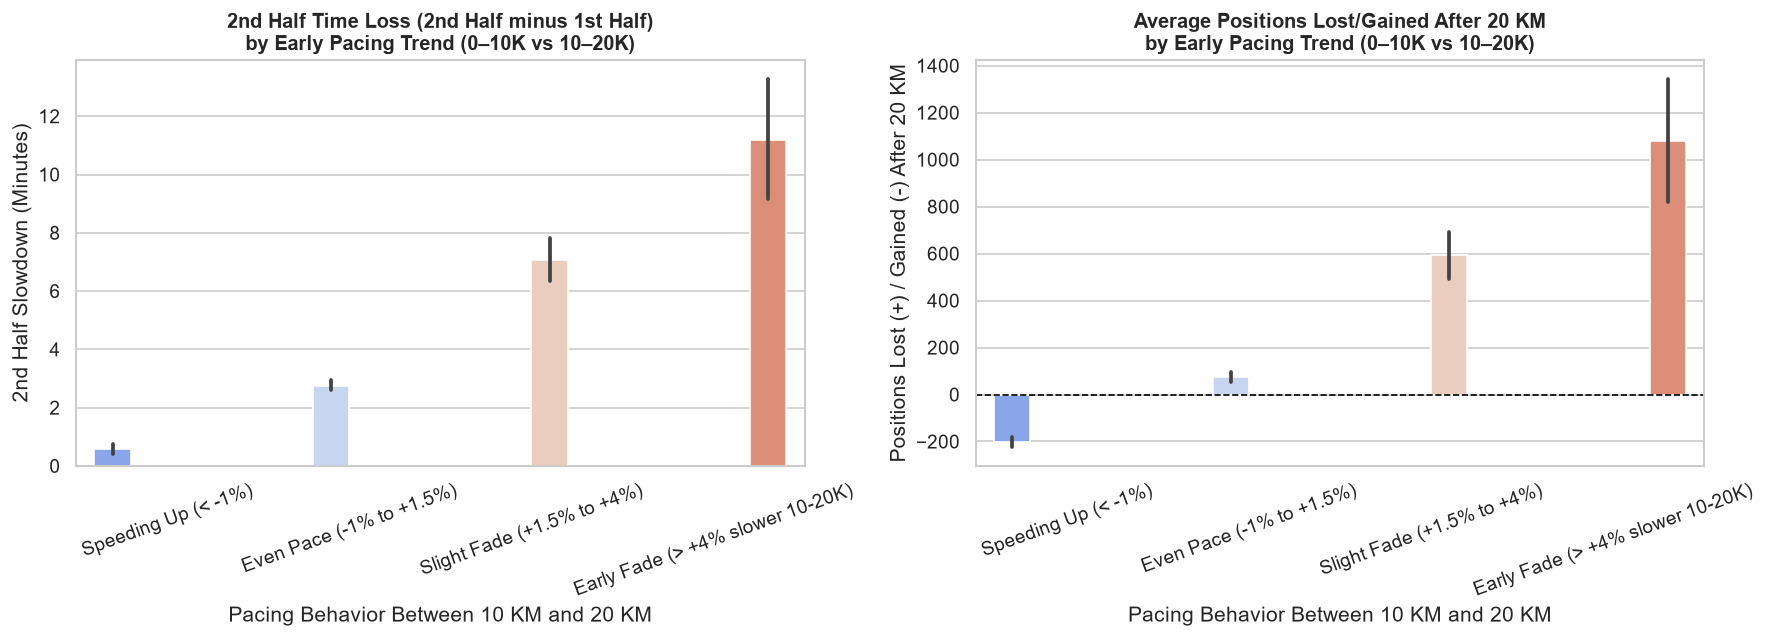

In [13]:
# Compare 1st Half (0-21.1km) vs 2nd Half (21.1-42.2km) split ratio as a function of early pace decay (10-20km vs 0-10km)
m_complete["first_10k_sec"] = m_complete["10km_sec"]
m_complete["second_10k_sec"] = m_complete["20km_sec"] - m_complete["10km_sec"]
m_complete["early_slowdown_pct"] = (m_complete["second_10k_sec"] - m_complete["first_10k_sec"]) / m_complete["first_10k_sec"] * 100.0

m_complete["first_half_sec"] = m_complete["21_1km_sec"]
m_complete["second_half_sec"] = m_complete["finish_seconds"] - m_complete["21_1km_sec"]
m_complete["second_half_slowdown_min"] = (m_complete["second_half_sec"] - m_complete["first_half_sec"]) / 60.0
m_complete["rank_drop_after_20k"] = m_complete["final_rank"] - m_complete["20km_rank"]  # positive = lost positions

m_complete["early_pacing_group"] = pd.cut(
    m_complete["early_slowdown_pct"],
    bins=[-50, -1.0, 1.5, 4.0, 100],
    labels=[
        "Speeding Up (< -1%)",
        "Even Pace (-1% to +1.5%)",
        "Slight Fade (+1.5% to +4%)",
        "Early Fade (> +4% slower 10-20K)",
    ],
)

pacing_summary = (
    m_complete.groupby("early_pacing_group", observed=True)
    .agg(
        runners=("bib", "count"),
        avg_2nd_half_slowdown_min=("second_half_slowdown_min", "mean"),
        avg_positions_lost_after_20k=("rank_drop_after_20k", "mean"),
    )
    .reset_index()
)
print(pacing_summary.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

sns.barplot(
    data=m_complete,
    x="early_pacing_group",
    y="second_half_slowdown_min",
    hue="early_pacing_group",
    palette="coolwarm",
    legend=False,
    ax=axes[0],
)
axes[0].axhline(0, color="black", linestyle="--", lw=1)
axes[0].set_title("2nd Half Time Loss (2nd Half minus 1st Half)\nby Early Pacing Trend (0–10K vs 10–20K)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Pacing Behavior Between 10 KM and 20 KM")
axes[0].set_ylabel("2nd Half Slowdown (Minutes)")
axes[0].tick_params(axis="x", rotation=20)

sns.barplot(
    data=m_complete,
    x="early_pacing_group",
    y="rank_drop_after_20k",
    hue="early_pacing_group",
    palette="coolwarm",
    legend=False,
    ax=axes[1],
)
axes[1].axhline(0, color="black", linestyle="--", lw=1)
axes[1].set_title("Average Positions Lost/Gained After 20 KM\nby Early Pacing Trend (0–10K vs 10–20K)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Pacing Behavior Between 10 KM and 20 KM")
axes[1].set_ylabel("Positions Lost (+) / Gained (-) After 20 KM")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

---
# Part 3: Which City Has the Fastest Runners on Average? (Cities with ? 20 Participants)

We analyze the `city` field across participants to find which cities (with **at least 20 finishers**) are the fastest:
1. **TCS Marathon (42.2 km):** Fastest cities by average finish time (and uncovering the surprising **"Nijmegen Elite Agency Effect"**!).
2. **Samsung Galaxy 7.5K:** Fastest cities by average finish time.
3. **All Races Combined:** Fastest cities by average running speed (`km/h`) and pace (`min/km`).

In [14]:
# Clean city names (normalize casing & Den Haag / 's-Gravenhage variants)
df["city_clean"] = df["city"].dropna().astype(str).str.strip().str.title()
city_aliases = {
    "'S-Gravenhage": "'s-Gravenhage (Den Haag)",
    "S-Gravenhage": "'s-Gravenhage (Den Haag)",
    "Den Haag": "'s-Gravenhage (Den Haag)",
    "The Hague": "'s-Gravenhage (Den Haag)",
}
df["city_clean"] = df["city_clean"].replace(city_aliases)
df["speed_kmh"] = (df["race_distance_meters"] / 1000.0) / (df["finish_seconds"] / 3600.0)

valid_city = df.dropna(subset=["finish_seconds", "city_clean"]).copy()
valid_city = valid_city[~valid_city["city_clean"].isin(["", "Nan", "None", "-"])]

def get_city_leaderboard(sub_df, min_runners=20, include_hours=True):
    grp = (
        sub_df.groupby("city_clean", as_index=False)
        .agg(
            participants=("finish_seconds", "count"),
            avg_finish_sec=("finish_seconds", "mean"),
            median_finish_sec=("finish_seconds", "median"),
            p25_finish_sec=("finish_seconds", lambda s: np.percentile(s, 25)),
            p75_finish_sec=("finish_seconds", lambda s: np.percentile(s, 75)),
            avg_speed_kmh=("speed_kmh", "mean"),
            avg_pace_min_km=("pace_min_per_km", "mean"),
        )
    )
    grp = grp[grp["participants"] >= min_runners].sort_values("avg_finish_sec").reset_index(drop=True)
    grp.index = grp.index + 1
    grp.index.name = "Rank"
    grp["avg_finish_time"] = grp["avg_finish_sec"].apply(lambda s: format_seconds(s, include_hours=include_hours))
    grp["median_finish_time"] = grp["median_finish_sec"].apply(lambda s: format_seconds(s, include_hours=include_hours))
    grp["p25_finish_time"] = grp["p25_finish_sec"].apply(lambda s: format_seconds(s, include_hours=include_hours))
    grp["p75_finish_time"] = grp["p75_finish_sec"].apply(lambda s: format_seconds(s, include_hours=include_hours))
    grp["avg_speed_kmh"] = grp["avg_speed_kmh"].round(2)
    grp["avg_pace_min_km"] = grp["avg_pace_min_km"].round(2)
    return grp

marathon_cities = get_city_leaderboard(valid_city[valid_city["race_name"] == "TCS Marathon"], min_runners=20, include_hours=True)
print(f"TCS Marathon ? Cities with >= 20 finishers ({len(marathon_cities)} cities):")
marathon_cities[["city_clean", "participants", "avg_finish_time", "median_finish_time", "p25_finish_time", "p75_finish_time", "avg_speed_kmh", "avg_pace_min_km"]]

TCS Marathon ? Cities with >= 20 finishers (20 cities):


,city_clean,participants,avg_finish_time,median_finish_time,p25_finish_time,p75_finish_time,avg_speed_kmh,avg_pace_min_km
Rank,,,,,,,,
1,Nijmegen,83,2:29:06,2:22:47,2:08:00,2:40:54,17.36,3.53
2,Manchester,22,2:58:29,2:57:32,2:49:09,3:09:32,14.27,4.23
3,Trondheim,31,3:01:17,2:59:09,2:52:48,3:09:22,14.05,4.30
4,Oslo,111,3:03:29,3:02:44,2:55:08,3:12:57,13.87,4.35
5,Rotterdam,67,3:03:47,3:05:38,2:56:16,3:14:43,13.88,4.36
6,Bristol,23,3:04:38,3:00:39,2:56:20,3:20:29,13.82,4.38
7,'s-Gravenhage (Den Haag),28,3:05:36,3:08:22,2:56:58,3:16:33,13.75,4.40
8,London,265,3:05:56,3:06:09,2:57:30,3:16:48,13.69,4.41
9,Dublin,43,3:06:34,3:11:17,2:59:37,3:17:54,13.67,4.42


### Why Is Nijmegen #1 in the TCS Marathon (`02:29:06` Average)? The "Elite Agency" Discovery!
At first glance, **Nijmegen** (`n = 83`, average finish time `2:29:06`, `17.36 km/h`) beats every other city by more than **29 minutes**! Why?
Let's inspect the runners registered under `city = "Nijmegen"`:

In [15]:
nijmegen_runners = valid_city[
    (valid_city["race_name"] == "TCS Marathon") & (valid_city["city_clean"] == "Nijmegen")
].sort_values("overall_position")

print("Country breakdown of 'Nijmegen' runners in TCS Marathon:")
print(nijmegen_runners["country"].value_counts().to_dict())

# Compare raw Nijmegen vs Dutch-only (country == 'NL') Nijmegen
nij_nl = nijmegen_runners[nijmegen_runners["country"] == "NL"]
print(f"\nAll Nijmegen (n={len(nijmegen_runners)}): Avg = {format_seconds(nijmegen_runners['finish_seconds'].mean())} | Median = {format_seconds(nijmegen_runners['finish_seconds'].median())}")
print(f"NL-only Nijmegen (n={len(nij_nl)}): Avg = {format_seconds(nij_nl['finish_seconds'].mean())} | Median = {format_seconds(nij_nl['finish_seconds'].median())}")

nijmegen_runners[["overall_position", "bib", "name", "country", "city", "chip_time"]].head(15)

Country breakdown of 'Nijmegen' runners in TCS Marathon:
{'NL': 30, 'ET': 16, 'KE': 13, 'GB': 6, 'BR': 4, 'FR': 2, 'ER': 2, 'IL': 2, 'JP': 1, 'ZW': 1, 'ZA': 1, 'TZ': 1, 'UG': 1, 'BH': 1, 'DE': 1, 'IT': 1}

All Nijmegen (n=83): Avg = 2:29:06 | Median = 2:22:47
NL-only Nijmegen (n=30): Avg = 2:49:56 | Median = 2:53:10


,overall_position,bib,name,country,city,chip_time
0,1,4,Lemi Berhanu,ET,Nijmegen,02:03:33
1,2,25,Nicholas Kipkorir,KE,Nijmegen,02:03:39
2,3,9,Patrick Mosin,KE,Nijmegen,02:03:58
3,4,14,Kalipus Lomwai,KE,Nijmegen,02:04:08
4,5,18,Sila Kiptoo,KE,Nijmegen,02:04:12
5,6,24,Justus Kangogo,KE,Nijmegen,02:04:24
6,7,17,Jonathan Korir,KE,Nijmegen,02:04:52
7,8,40,Isaia Lasoi,KE,Nijmegen,02:04:57
8,9,15,Yohei Ikeda,JP,Nijmegen,02:05:16
9,10,12,Yihunilign Adane,ET,Nijmegen,02:05:16


In [16]:
# Also compute the Samsung Galaxy 7.5K city leaderboard (>= 20 participants)
r75_cities = get_city_leaderboard(valid_city[valid_city["race_name"] == "Samsung Galaxy 7.5K"], min_runners=20, include_hours=False)
print(f"Samsung Galaxy 7.5K ? Top 20 Fastest Cities with >= 20 finishers (out of {len(r75_cities)} cities):")
r75_cities[["city_clean", "participants", "avg_finish_time", "median_finish_time", "p25_finish_time", "p75_finish_time", "avg_speed_kmh", "avg_pace_min_km"]].head(20)

Samsung Galaxy 7.5K ? Top 20 Fastest Cities with >= 20 finishers (out of 42 cities):


,city_clean,participants,avg_finish_time,median_finish_time,p25_finish_time,p75_finish_time,avg_speed_kmh,avg_pace_min_km
Rank,,,,,,,,
1,Beverwijk,21,43:16,43:20,38:21,47:24,10.71,5.77
2,London,33,43:37,43:20,40:25,47:54,10.66,5.82
3,Volendam,27,43:48,42:57,36:59,48:13,10.64,5.84
4,Ouderkerk Aan De Amstel,24,44:17,45:48,38:59,47:56,10.33,5.90
5,Heerhugowaard,25,44:25,44:31,38:51,48:10,10.41,5.92
6,Zwaag,22,44:51,43:48,39:54,48:16,10.25,5.98
7,Delft,39,44:57,46:09,39:42,49:53,10.22,5.99
8,Alphen Aan Den Rijn,44,44:58,44:04,39:58,49:21,10.24,6.00
9,São Paulo,24,45:02,44:31,41:29,49:12,10.16,6.00


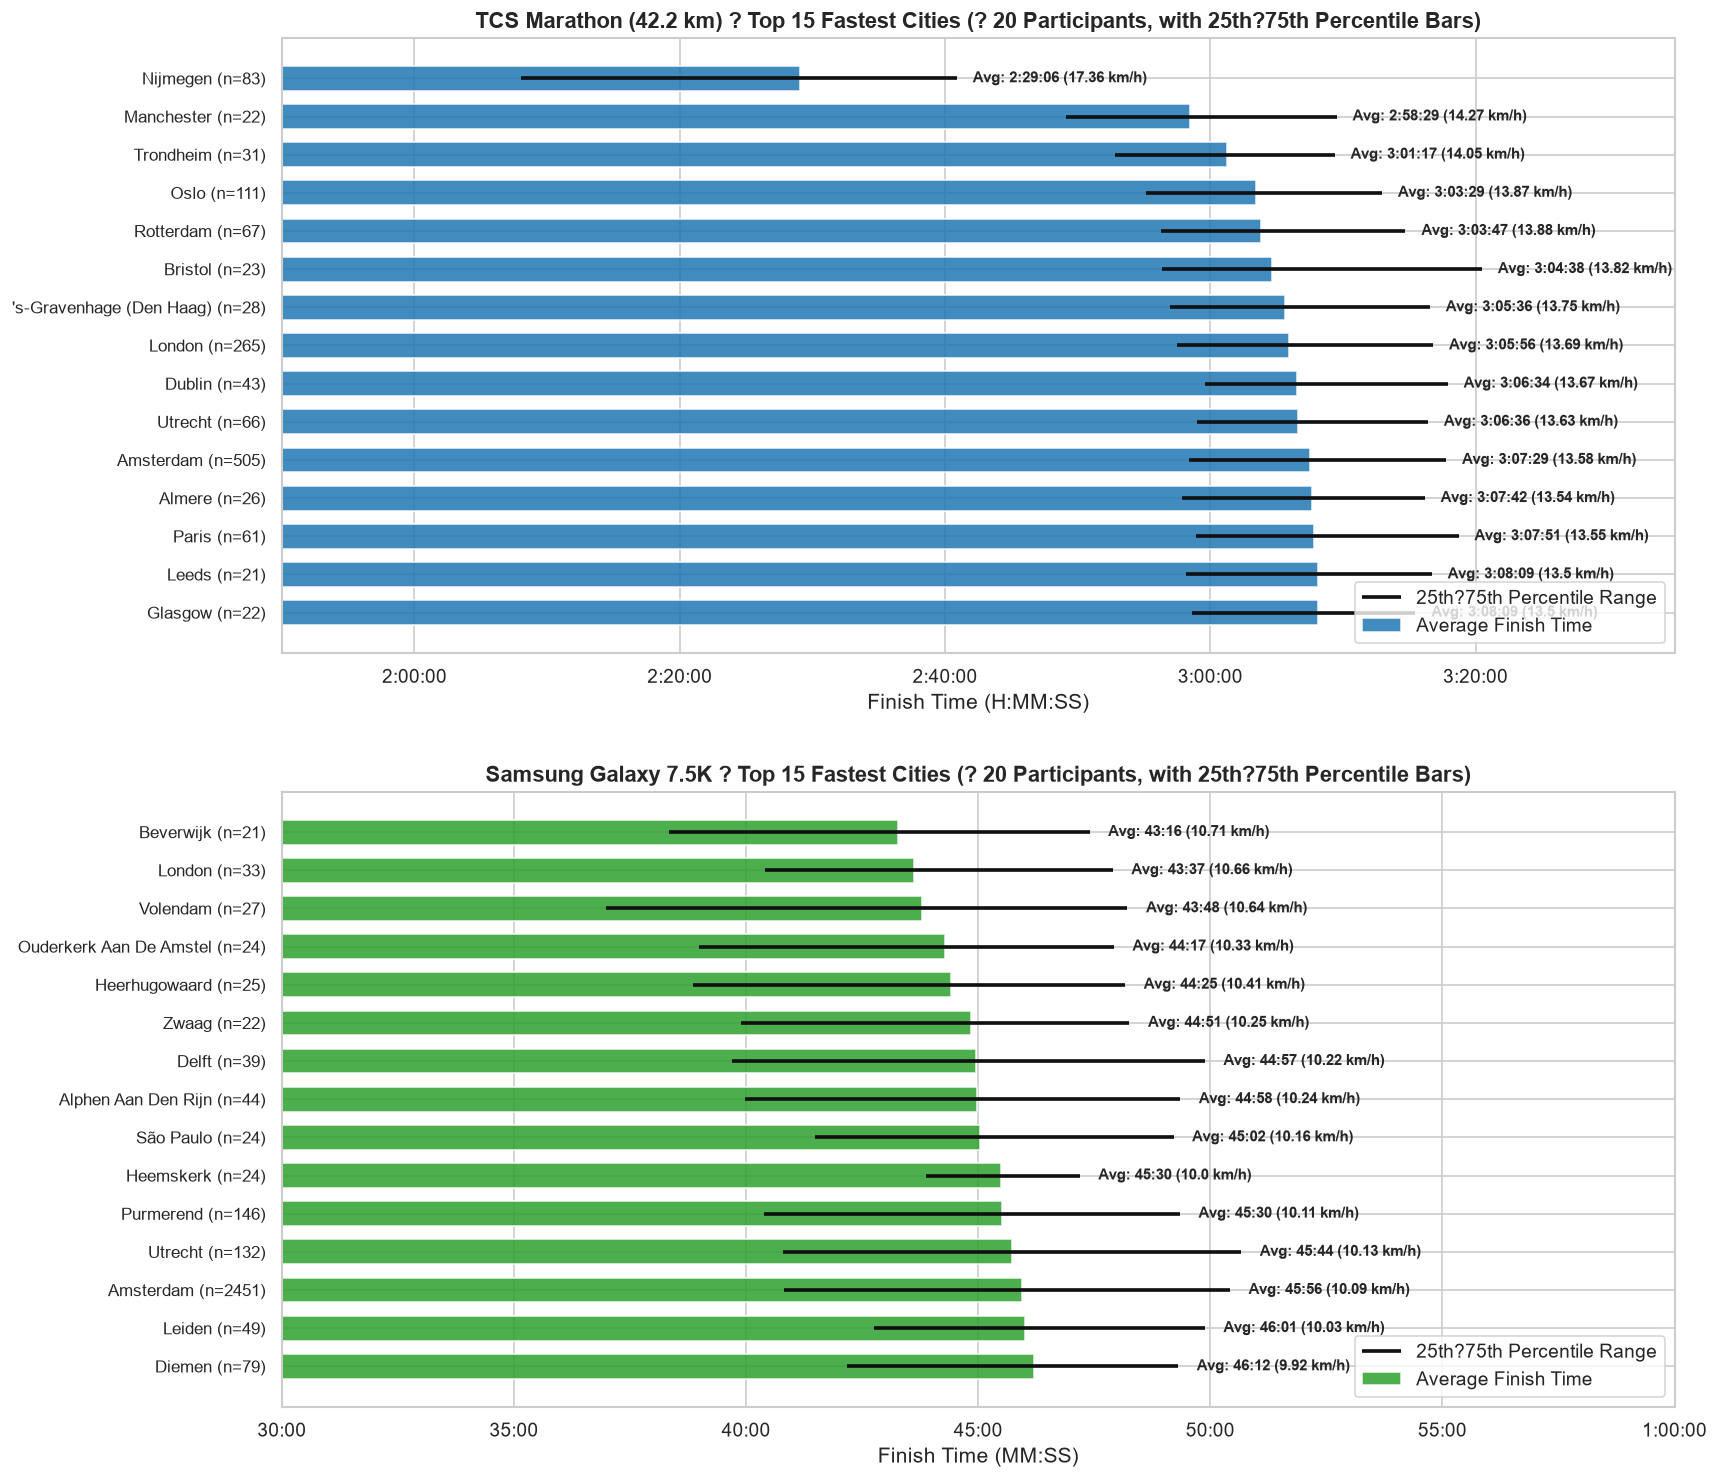

In [17]:
# Plot Top 15 Fastest Cities (>= 20 participants) for TCS Marathon and Samsung Galaxy 7.5K stacked vertically
fig, axes = plt.subplots(2, 1, figsize=(15, 13))

# 1. TCS Marathon Top 15 Cities
m_top15 = marathon_cities.head(15).copy()
m_top15["avg_min"] = m_top15["avg_finish_sec"] / 60.0
m_top15["p25_min"] = m_top15["p25_finish_sec"] / 60.0
m_top15["p75_min"] = m_top15["p75_finish_sec"] / 60.0
m_top15["label"] = m_top15.apply(lambda r: f"{r['city_clean']} (n={r['participants']})", axis=1)

y_pos_m = np.arange(len(m_top15))
axes[0].barh(y_pos_m, m_top15["avg_min"], color="#1f77b4", alpha=0.85, height=0.65, label="Average Finish Time")
axes[0].hlines(y_pos_m, m_top15["p25_min"], m_top15["p75_min"], color="#111111", lw=2.2, label="25th?75th Percentile Range")
for yv, row in zip(y_pos_m, m_top15.itertuples()):
    axes[0].annotate(
        f"Avg: {row.avg_finish_time} ({row.avg_speed_kmh} km/h)",
        (row.p75_min + 1.2, yv),
        va="center",
        fontsize=9,
        fontweight="bold",
    )
axes[0].invert_yaxis()
axes[0].set_yticks(y_pos_m)
axes[0].set_yticklabels(m_top15["label"], fontsize=10)
axes[0].xaxis.set_major_formatter(ticker.FuncFormatter(lambda mins, pos: format_seconds(mins * 60, include_hours=True)))
axes[0].set_title("TCS Marathon (42.2 km) ? Top 15 Fastest Cities (? 20 Participants, with 25th?75th Percentile Bars)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Finish Time (H:MM:SS)")
axes[0].set_xlim(110, 215)
axes[0].legend(loc="lower right")

# 2. Samsung Galaxy 7.5K Top 15 Cities
r_top15 = r75_cities.head(15).copy()
r_top15["avg_min"] = r_top15["avg_finish_sec"] / 60.0
r_top15["p25_min"] = r_top15["p25_finish_sec"] / 60.0
r_top15["p75_min"] = r_top15["p75_finish_sec"] / 60.0
r_top15["label"] = r_top15.apply(lambda r: f"{r['city_clean']} (n={r['participants']})", axis=1)

y_pos_r = np.arange(len(r_top15))
axes[1].barh(y_pos_r, r_top15["avg_min"], color="#2ca02c", alpha=0.85, height=0.65, label="Average Finish Time")
axes[1].hlines(y_pos_r, r_top15["p25_min"], r_top15["p75_min"], color="#111111", lw=2.2, label="25th?75th Percentile Range")
for yv, row in zip(y_pos_r, r_top15.itertuples()):
    axes[1].annotate(
        f"Avg: {row.avg_finish_time} ({row.avg_speed_kmh} km/h)",
        (row.p75_min + 0.4, yv),
        va="center",
        fontsize=9,
        fontweight="bold",
    )
axes[1].invert_yaxis()
axes[1].set_yticks(y_pos_r)
axes[1].set_yticklabels(r_top15["label"], fontsize=10)
axes[1].xaxis.set_major_formatter(ticker.FuncFormatter(lambda mins, pos: format_seconds(mins * 60, include_hours=False)))
axes[1].set_title("Samsung Galaxy 7.5K ? Top 15 Fastest Cities (? 20 Participants, with 25th?75th Percentile Bars)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Finish Time (MM:SS)")
axes[1].set_xlim(30, 60)
axes[1].legend(loc="lower right")

plt.tight_layout(pad=2.5)
plt.show()